# 02 · Ingeniería de variables: de la base larga a la matriz de unidades
## Idea central
Cada fila del clustering será un **segmento** `(entidad, distrito, tipo de sección, sexo, grupo de edad)`, con una tasa por cada elección disponible.

El notebook detecta automáticamente los años presentes en `ccpc_limpio.csv.gz`. **Si solo se descargó 2024, el análisis será transversal**: no se pueden interpretar tendencias ni diferencias entre elecciones hasta añadir los archivos de 2009, 2012, 2015, 2018 y 2021.

Las variables sociodemográficas se usan para caracterizar los grupos, no para formar el clustering.

In [5]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import utils as U

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.3f}".format

FUENTE = (U.DIR_PROC / "FUENTE.txt").read_text().strip()
if FUENTE != "REAL":
    print("⚠️ Estás trabajando con DATOS SINTÉTICOS (solo prueba).")
df = pd.read_csv(U.DIR_PROC / "ccpc_limpio.csv.gz")
ANIOS = sorted(pd.to_numeric(df["anio"], errors="coerce").dropna().astype(int).unique().tolist())
COLS_TASA = [f"tasa_{a}" for a in ANIOS]
print(f"{len(df):,} filas cargadas | años disponibles: {ANIOS}")
if len(ANIOS) < 6:
    print("⚠️ Hay menos de seis elecciones. Las comparaciones históricas no serán completas.")


143,779 filas cargadas | años disponibles: [2009, 2012, 2015, 2018, 2021, 2024]


In [6]:
# ---- Parámetros de calidad ----
MIN_LISTA = 30
MAX_FALTANTES = max(0, len(ANIOS) - 1)

# Una fila por segmento y una columna de tasa por elección disponible.
claves = ["entidad", "distrito", "tipo_seccion", "sexo", "grupo_edad"]
base = df.copy()
base["anio"] = pd.to_numeric(base["anio"], errors="coerce").astype("Int64")
base["tasa"] = np.where(base["lista_nominal"] > 0,
                        base["participantes"] / base["lista_nominal"], np.nan)

# Pivotear conteos por año antes de calcular tasas evita promediar tasas de registros.
piv_ln = base.pivot_table(index=claves, columns="anio", values="lista_nominal",
                          aggfunc="sum", observed=False)
piv_sv = base.pivot_table(index=claves, columns="anio", values="participantes",
                          aggfunc="sum", observed=False)
tasas = piv_sv.div(piv_ln.where(piv_ln > 0))
tasas.columns = [f"tasa_{int(a)}" for a in tasas.columns]
ln_media = piv_ln.mean(axis=1)
faltantes = tasas.isna().sum(axis=1)
mascara = (ln_media >= MIN_LISTA) & (faltantes <= MAX_FALTANTES)
tasas = tasas.loc[mascara].copy()
ln_media = ln_media.loc[mascara]
unidades = tasas.reset_index()
unidades["ln_media"] = ln_media.to_numpy()

# Imputación de tasas faltantes por mediana de grupo de edad y sexo; si no existe,
# se usa la mediana global de esa elección.
for col in COLS_TASA:
    if unidades[col].isna().any():
        med_grupo = unidades.groupby(["grupo_edad", "sexo"], dropna=False)[col].transform("median")
        unidades[col] = unidades[col].fillna(med_grupo).fillna(unidades[col].median())

# Variables derivadas: si faltan elecciones de una categoría, se usan solo las disponibles.
anios_pres = [a for a in ANIOS if a in [2012, 2018, 2024]]
anios_interm = [a for a in ANIOS if a in [2009, 2015, 2021]]
cols_pres = [f"tasa_{a}" for a in anios_pres]
cols_interm = [f"tasa_{a}" for a in anios_interm]
unidades["tasa_media"] = unidades[COLS_TASA].mean(axis=1)
unidades["tasa_pres"] = unidades[cols_pres].mean(axis=1) if cols_pres else np.nan
unidades["tasa_interm"] = unidades[cols_interm].mean(axis=1) if cols_interm else np.nan
unidades["brecha_pres_interm"] = unidades["tasa_pres"] - unidades["tasa_interm"]
unidades["volatilidad"] = unidades[COLS_TASA].std(axis=1, ddof=0) if len(COLS_TASA) > 1 else 0.0
unidades["tendencia"] = (unidades[COLS_TASA].to_numpy() @ np.zeros(len(COLS_TASA))
                         if len(COLS_TASA) == 1 else
                         np.polyfit(np.array(ANIOS, dtype=float), unidades[COLS_TASA].to_numpy().T, 1)[0])

unidades["edad_inferior"] = unidades["grupo_edad"].map(U.edad_inferior)
unidades["ciclo_vida"] = unidades["edad_inferior"].map(U.ciclo_vida)
unidades["region"] = unidades["entidad"].map(U.REGION_POR_ENTIDAD).fillna("Sin región")

info = {
    "segmentos iniciales": len(piv_ln),
    "segmentos descartados por tamaño o faltantes": int((~mascara).sum()),
    "segmentos conservados": len(unidades),
    "años disponibles": ", ".join(map(str, ANIOS)),
}
if unidades.empty:
    raise ValueError(
        "La matriz de unidades quedó vacía. Revisa MIN_LISTA, MAX_FALTANTES y los años disponibles."
    )
pd.Series(info, name="conteo").to_frame()


,conteo
segmentos iniciales,24722
segmentos descartados por tamaño o faltantes,612
segmentos conservados,24110
años disponibles,"2009, 2012, 2015, 2018, 2021, 2024"


In [7]:
print("Forma de la matriz:", unidades.shape)
unidades.head()

Forma de la matriz: (24110, 21)


,entidad,distrito,tipo_seccion,sexo,grupo_edad,tasa_2009,tasa_2012,tasa_2015,tasa_2018,tasa_2021,...,ln_media,tasa_media,tasa_pres,tasa_interm,brecha_pres_interm,volatilidad,tendencia,edad_inferior,ciclo_vida,region
0,AGUASCALIENTES,1.000,Mixta,Hombres,18-19,0.386,0.549,0.299,0.495,0.491,...,"2,623.667",0.458,0.523,0.392,0.131,0.087,0.007,18.000,Jóvenes (18-29),Circ. 2
1,AGUASCALIENTES,1.000,Mixta,Hombres,20-24,0.266,0.423,0.227,0.402,0.386,...,"7,394.167",0.353,0.413,0.293,0.120,0.077,0.008,20.000,Jóvenes (18-29),Circ. 2
2,AGUASCALIENTES,1.000,Mixta,Hombres,25-29,0.263,0.391,0.195,0.397,0.357,...,"6,783.000",0.330,0.389,0.272,0.118,0.076,0.006,25.000,Jóvenes (18-29),Circ. 2
3,AGUASCALIENTES,1.000,Mixta,Hombres,30-34,0.284,0.445,0.245,0.448,0.398,...,"6,148.500",0.373,0.438,0.309,0.130,0.080,0.007,30.000,Adultos (30-49),Circ. 2
4,AGUASCALIENTES,1.000,Mixta,Hombres,35-39,0.362,0.539,0.305,0.507,0.433,...,"5,753.667",0.436,0.505,0.367,0.138,0.081,0.004,35.000,Adultos (30-49),Circ. 2


## Diagnóstico de las variables
Antes de agrupar hay que ver **cómo se distribuyen** y **qué tan correlacionadas** están las tasas.
Si `tasa_2012` y `tasa_2018` tienen correlación 0.9, comparten casi la misma información: es normal en series electorales y
es justo la razón por la que luego estandarizamos y revisamos PCA.

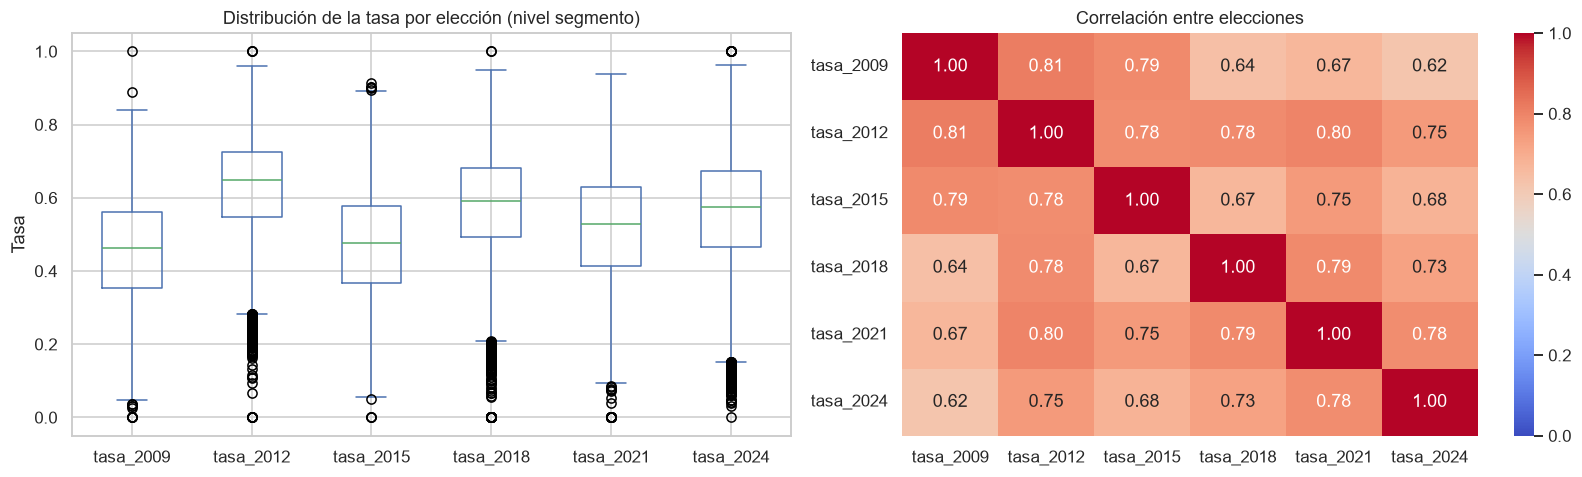

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
unidades[U.COLS_TASA].plot(kind="box", ax=axes[0])
axes[0].set(title="Distribución de la tasa por elección (nivel segmento)", ylabel="Tasa")
sns.heatmap(unidades[U.COLS_TASA].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Correlación entre elecciones")
plt.tight_layout(); plt.show()

In [9]:
cols_der = ["tasa_media", "tasa_pres", "tasa_interm", "brecha_pres_interm", "volatilidad", "tendencia", "ln_media"]
unidades[cols_der].describe().T

,count,mean,std,min,25%,50%,75%,max
tasa_media,"24,110.000",0.536,0.123,0.116,0.451,0.548,0.630,0.881
tasa_pres,"24,110.000",0.590,0.124,0.109,0.506,0.603,0.686,0.917
tasa_interm,"24,110.000",0.482,0.131,0.073,0.388,0.491,0.580,0.858
brecha_pres_interm,"24,110.000",0.108,0.063,-0.274,0.065,0.110,0.149,0.426
volatilidad,"24,110.000",0.085,0.030,0.008,0.064,0.082,0.101,0.307
tendencia,"24,110.000",0.003,0.008,-0.034,-0.002,0.003,0.008,0.043
ln_media,"24,110.000","3,665.159","4,268.040",30.000,706.375,"1,947.583","4,948.750","23,163.500"


In [10]:
# Cobertura de categorías de caracterización (revisa que no haya "Sin región" ni "Sin dato" masivos)
for c in ["region", "ciclo_vida", "tipo_seccion", "sexo"]:
    print(unidades[c].value_counts(dropna=False).to_string(), "\n")

region
Circ. 2    5399
Circ. 3    5372
Circ. 1    4941
Circ. 5    4662
Circ. 4    3736 

ciclo_vida
Mayores (65+)           7791
Adultos (30-49)         6544
Jóvenes (18-29)         4892
Mediana edad (50-64)    4883 

tipo_seccion
Urbana    9210
Mixta     7815
Rural     7085 

sexo
Mujeres    12062
Hombres    12048 



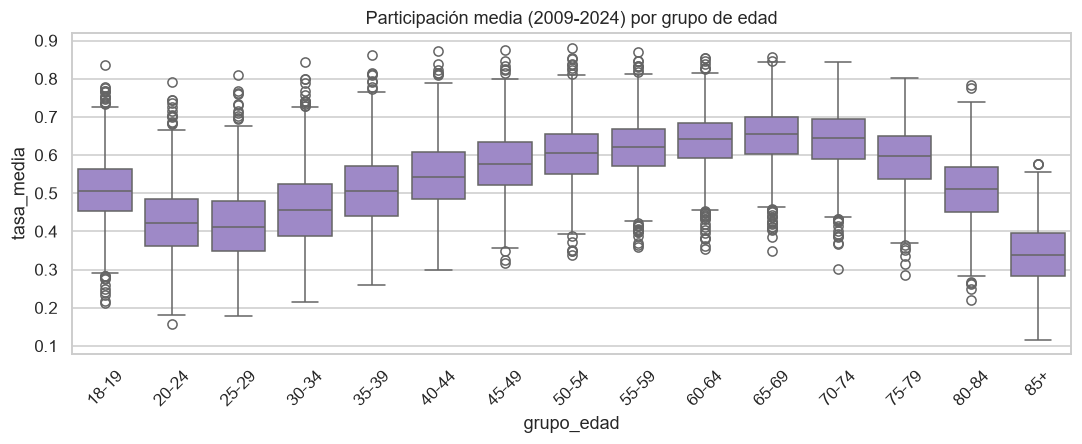

In [11]:
# Relación edad - participación media (¿la edad explica mucho? esto motiva caracterizar por edad)
orden = U.orden_grupos_edad(unidades["grupo_edad"])
plt.figure(figsize=(10, 4.2))
sns.boxplot(data=unidades, x="grupo_edad", y="tasa_media", order=orden, color="#9b7fd1")
plt.xticks(rotation=45); plt.title("Participación media (2009-2024) por grupo de edad"); plt.tight_layout(); plt.show()

In [12]:
unidades.to_csv(U.DIR_PROC / "unidades.csv", index=False)
print("Guardado:", U.DIR_PROC / "unidades.csv", unidades.shape)

Guardado: C:\Users\Pro12\Desktop\INE\data\processed\unidades.csv (24110, 21)
